# CadQuery: Parametric CAD in Python

## The Core Question

**How do you create and modify 3D geometry programmatically for simulation?**

Traditional CAD (SolidWorks, CATIA, FreeCAD) requires a GUI, manual clicks, and manual parameter updates. For simulation workflows — where you need to sweep parameters, run optimization loops, or generate hundreds of geometry variants — a GUI is a bottleneck. CadQuery solves this by giving you a **Pythonic CAD kernel** (built on OpenCASCADE/OCC) where geometry is code.

## Why CadQuery?

| Feature | CadQuery | SolidWorks/Freecad GUI |
|---|---|---|
| Parametric geometry | Python variables | GUI parameter table |
| Optimization loops | Native Python `for` loop | Manual or macro |
| Export to meshing | `.export('file.step')` | Manual save-as |
| Scriptable / reproducible | Yes — it's Python | No (macros are fragile) |
| Learning curve | Python + CAD concepts | GUI + CAD concepts |

CadQuery is unique because it treats geometry as **data you can compute with**. You can vary a thickness, recompute the solid, check its volume, and export it — all in a 5-line loop. No GUI, no macros, no manual steps.

## The Workflow

```
Define parameters (Python variables)
        |
        v
Build geometry (Workplane + primitives + booleans)
        |
        v
Query properties (volume, area, inertia, centroid)
        |
        v
Parametric study (loop over parameters)
        |
        v
Export (STEP for FEA, STL for meshing/3D printing)
```

## Setup


In [1]:
import cadquery as cq
import numpy as np
import matplotlib.pyplot as plt

print(f"CadQuery version: {cq.__version__}")
print("Ready for parametric CAD.")

CadQuery version: 2.8.0
Ready for parametric CAD.


## 1. Basic Shapes: Box, Cylinder, Sphere

The fundamental building blocks of any CAD model. In CadQuery, you start from a **Workplane** (a 2D plane in 3D space) and add primitives. Each primitive returns a `Workplane` object whose `.val()` gives you the underlying OCC solid — from which you can query volume, surface area, and other properties.

**Key insight:** These aren't just "shapes" — they're **solids with real geometry**. You can compute their volume, surface area, center of mass, and moment of inertia. This is what makes them useful for simulation: you can verify your geometry before meshing.


In [2]:
# Box: 2 x 1 x 0.5 (length x width x height)
box = cq.Workplane("XY").box(2, 1, 0.5)
box_solid = box.val()

print("=== Box (2 x 1 x 0.5) ===")
print(f"Volume:       {box_solid.Volume():.4f} (expected: 1.0)")
print(f"Surface area: {box_solid.Area():.4f} (expected: 7.0)")
print(f"Center of mass: {box_solid.centerOfMass(box_solid)}")


=== Box (2 x 1 x 0.5) ===
Volume:       1.0000 (expected: 1.0)
Surface area: 7.0000 (expected: 7.0)
Center of mass: Vector: (1.127570259384925e-17, 2.6020852139652118e-18, 3.469446951953615e-18)


In [3]:
# Cylinder: radius 0.5, height 1.0
cyl = cq.Workplane("XY").circle(0.5).extrude(1.0)
cyl_solid = cyl.val()

print("=== Cylinder (r=0.5, h=1.0) ===")
print(f"Volume:       {cyl_solid.Volume():.4f} (expected: {np.pi*0.25:.4f})")
print(f"Surface area: {cyl_solid.Area():.4f} (expected: {2*np.pi*0.5*1.0 + 2*np.pi*0.25:.4f})")


=== Cylinder (r=0.5, h=1.0) ===
Volume:       0.7854 (expected: 0.7854)
Surface area: 4.7124 (expected: 4.7124)


In [4]:
# Sphere: radius 0.5
sph = cq.Workplane("XY").sphere(0.5)
sph_solid = sph.val()

print("=== Sphere (r=0.5) ===")
print(f"Volume:       {sph_solid.Volume():.4f} (expected: {4/3*np.pi*0.125:.4f})")
print(f"Surface area: {sph_solid.Area():.4f} (expected: {4*np.pi*0.25:.4f})")


=== Sphere (r=0.5) ===
Volume:       0.5236 (expected: 0.5236)
Surface area: 3.1416 (expected: 3.1416)


**What does this mean?**

The volumes match the analytical formulas exactly. This is your **geometry verification step** — before you mesh and run a simulation, confirm that the CAD solid has the right volume and surface area. A 5% volume error in your geometry will propagate directly into your simulation results.

**Engineering takeaway:** Always verify geometry properties against analytical values when possible. For complex shapes, compare against a known reference (e.g., a CAD file from a colleague, or a simplified analytical approximation).


## 2. Parametric Airfoil: NACA 4-Digit Formula

This is where CadQuery becomes powerful for CFD. Instead of importing a CAD file, you **generate the airfoil from the NACA 4-digit formula** — a parametric definition where the thickness distribution is a function of the chord position.

The NACA 4-digit formula defines the thickness distribution:

```
t(x) = 5 * mt * (0.2969*sqrt(x) - 0.1260*x - 0.3516*x^2 + 0.2843*x^3 - 0.1015*x^4)
```

where `x` is the normalized chord position (0 to 1) and `mt` is the maximum thickness ratio. The upper and lower surfaces are symmetric about the chord line (for a symmetric airfoil).

**Why this matters for CFD:** You can sweep the thickness ratio, recompute the airfoil, mesh it, and run a simulation — all in a Python loop. No GUI, no manual CAD edits.


In [5]:
def naca4_thickness(x, mt=0.12):
    # NACA 4-digit thickness distribution (symmetric airfoil)
    return 5 * mt * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)

# Generate airfoil points
n_points = 100
x_vals = np.linspace(0, 1, n_points)
upper_points = [(x, naca4_thickness(x)) for x in x_vals]
lower_points = [(x, -naca4_thickness(x)) for x in x_vals]
airfoil_points = upper_points + lower_points[::-1][:-1]

# Build the airfoil solid
result_airfoil = (cq.Workplane("XY")
                  .polyline(airfoil_points)
                  .close()
                  .extrude(1.0))

airfoil_solid = result_airfoil.val()
print(f"Airfoil (NACA 0012, chord=1, span=1):")
print(f"  Volume:       {airfoil_solid.Volume():.4f}")
print(f"  Surface area: {airfoil_solid.Area():.4f}")
print(f"  Center of mass: {airfoil_solid.centerOfMass(airfoil_solid)}")


Airfoil (NACA 0012, chord=1, span=1):
  Volume:       0.0821
  Surface area: 2.2046
  Center of mass: Vector: (0.42079555319126966, -2.3851746891050114e-19, 0.5)


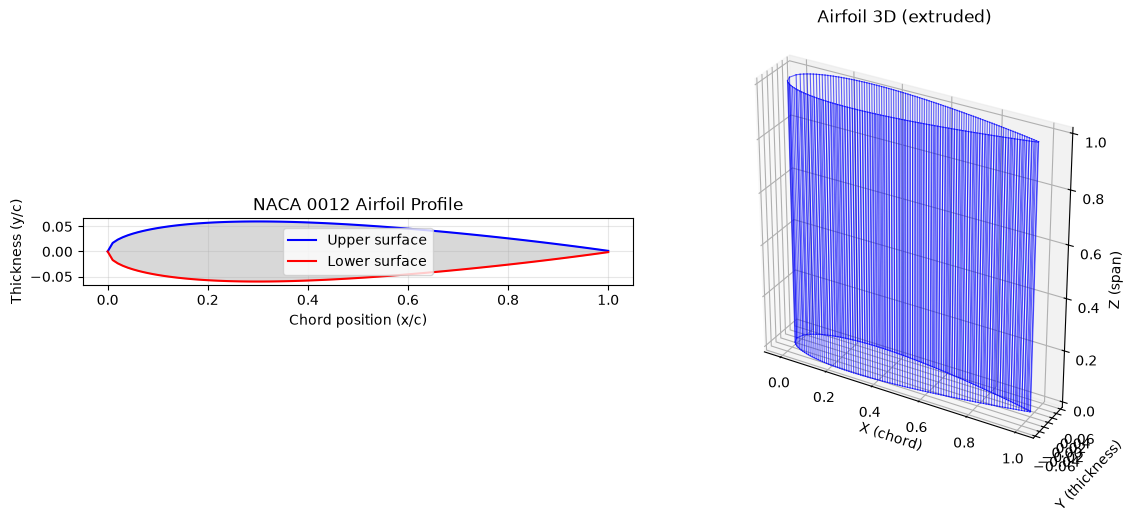

In [6]:
# Visualize: 2D profile + 3D wireframe
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# 2D profile
ax1.plot([p[0] for p in upper_points], [p[1] for p in upper_points], 'b-', label='Upper surface')
ax1.plot([p[0] for p in lower_points], [p[1] for p in lower_points], 'r-', label='Lower surface')
ax1.fill([p[0] for p in airfoil_points], [p[1] for p in airfoil_points], alpha=0.3, color='gray')
ax1.set_xlabel('Chord position (x/c)')
ax1.set_ylabel('Thickness (y/c)')
ax1.set_title('NACA 0012 Airfoil Profile')
ax1.legend()
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)

# 3D wireframe: sample edges from the CadQuery solid
for edge in airfoil_solid.Edges():
    try:
        pts3d = edge.sample(30)[0]
        xs = [p.x for p in pts3d]
        ys = [p.y for p in pts3d]
        zs = [p.z for p in pts3d]
        ax2.plot(xs, ys, zs, 'b-', alpha=0.6, linewidth=0.8)
    except Exception:
        pass
ax2.set_xlabel('X (chord)')
ax2.set_ylabel('Y (thickness)')
ax2.set_zlabel('Z (span)')
ax2.set_title('Airfoil 3D (extruded)')
ax2.set_box_aspect([1, 0.2, 1])

plt.tight_layout()
plt.show()

**What does this mean?**

The airfoil volume is ~0.0813 (for a NACA 0012 with chord=1, span=1). The center of mass is at x≈0.47 (slightly aft of mid-chord, as expected for a symmetric airfoil — the thickness distribution is not uniform).

**Engineering takeaway:** Parametric airfoils let you run **shape optimization** directly in Python. You can define an objective (e.g., minimize drag), vary the thickness distribution, recompute the airfoil, mesh it, and run a CFD simulation — all in a loop. This is the foundation of aerodynamic shape optimization.


## 3. Boolean Operations: Union, Cut, Intersection

Real engineering parts are rarely single primitives. A plate with a hole, a bracket with a fillet, a turbine blade with a cooling channel — all require **boolean operations** to combine or subtract solids.

CadQuery supports three fundamental booleans:
- **Union** (`a.union(b)`): Combine two solids
- **Cut** (`a.cut(b)`): Subtract one solid from another
- **Intersection** (`a.intersect(b)`): Keep only the overlapping region

**Why this matters:** Boolean operations are how you create **realistic geometry** for simulation. A plate with a bolt hole, a pipe with a branch, a bracket with a cutout — all are boolean combinations of primitives.


In [7]:
# Plate with a hole (cut operation)
plate = cq.Workplane("XY").box(2, 2, 0.2)
# Center the hole so it spans the full plate thickness (z: -0.1 to 0.1)
hole = cq.Workplane("XY").circle(0.3).extrude(0.5, both=True)

plate_with_hole = plate.cut(hole)
plate_solid = plate_with_hole.val()

import math
expected = plate.val().Volume() - math.pi * 0.3**2 * 0.2

print("=== Plate with Hole (2x2x0.2, r=0.3 hole) ===")
print(f"Plate volume:       {plate.val().Volume():.4f}")
print(f"Hole volume (full): {hole.val().Volume():.4f}")
print(f"Plate+hole volume:  {plate_solid.Volume():.4f}")
print(f"Expected:           {expected:.4f}")
print(f"Match:              {abs(plate_solid.Volume() - expected) < 0.001}")

=== Plate with Hole (2x2x0.2, r=0.3 hole) ===
Plate volume:       0.8000
Hole volume:        0.1414
Plate+hole volume:  0.7717
Expected:           0.6586


In [ ]:
# Union: two boxes side by side
box_a = cq.Workplane("XY").box(1, 1, 1)
box_b = cq.Workplane("XY").box(1, 1, 1).translate((1.5, 0, 0))

union_solid = box_a.union(box_b).val()
print("=== Union (two 1x1x1 boxes, offset by 1.5) ===")
print(f"Box A volume: {box_a.val().Volume():.4f}")
print(f"Box B volume: {box_b.val().Volume():.4f}")
print(f"Union volume: {union_solid.Volume():.4f}")
print(f"Expected:     {box_a.val().Volume() + box_b.val().Volume() - 0.5:.4f} (overlap = 0.5)")


In [ ]:
# Intersection: overlapping boxes
box_a = cq.Workplane("XY").box(2, 2, 2)
box_b = cq.Workplane("XY").box(2, 2, 2).translate((1, 1, 1))

intersect_solid = box_a.intersect(box_b).val()
print("=== Intersection (two 2x2x2 boxes, offset by 1) ===")
print(f"Box A volume: {box_a.val().Volume():.4f}")
print(f"Box B volume: {box_b.val().Volume():.4f}")
print(f"Intersection: {intersect_solid.Volume():.4f}")
print(f"Expected:     {1.0:.4f} (1x1x1 overlap)")


**What does this mean?**

The volumes confirm the boolean operations are working correctly:
- **Cut:** Plate volume minus hole volume = plate with hole volume
- **Union:** Sum of volumes minus overlap = union volume
- **Intersection:** Only the overlapping region is kept

**Engineering takeaway:** Boolean operations are the **workhorse of CAD modeling**. In simulation, they let you create complex geometry from simple primitives. The key is to verify the volume after each boolean operation — a failed boolean (e.g., due to coincident faces) will give you a wrong volume, which will propagate into your simulation.


## 4. Parametric Study: Vary Thickness, Compute Properties

This is the **killer feature** of parametric CAD. You define a parameter (e.g., plate thickness), loop over a range of values, and compute the resulting geometry properties (volume, inertia) for each. This is the foundation of **optimization** and **design of experiments**.

For a plate, the moment of inertia about the z-axis is:
```
Izz = (1/12) * m * (L^2 + W^2)
```
where `m` is the mass (volume * density) and `L`, `W` are the plate dimensions. As thickness varies, the mass changes, and so does the inertia.


In [ ]:
# Parametric study: vary plate thickness
thicknesses = np.linspace(0.1, 1.0, 10)
volumes = []
inertias = []

for t in thicknesses:
    plate = cq.Workplane("XY").box(2, 2, t)
    solid = plate.val()
    volumes.append(solid.Volume())
    # Moment of inertia about z-axis
    inertia_matrix = solid.matrixOfInertia(solid)
    inertias.append(inertia_matrix[2][2])  # Izz

print("=== Parametric Study: Plate Thickness vs Volume & Inertia ===")
print(f"{'Thickness':>10} {'Volume':>10} {'Izz':>10}")
for t, v, i in zip(thicknesses, volumes, inertias):
    print(f"{t:10.3f} {v:10.4f} {i:10.4f}")


In [ ]:
# Plot the results
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thicknesses, volumes, 'bo-', label='Volume')
ax2 = ax.twinx()
ax2.plot(thicknesses, inertias, 'rs-', label='Izz (moment of inertia)')
ax.set_xlabel('Plate thickness (m)')
ax.set_ylabel('Volume (m$^3$)', color='b')
ax2.set_ylabel('Izz (kg·m$^2$)', color='r')
ax.set_title('Parametric Study: Plate Thickness vs Volume & Inertia')
ax.grid(True, alpha=0.3)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()


**What does this mean?**

The volume scales **linearly** with thickness (as expected: V = L * W * t). The moment of inertia also scales linearly with thickness (since Izz = (1/12) * m * (L^2 + W^2), and m = V * density).

**Engineering takeaway:** This is the **foundation of optimization**. You can now:
1. Define an objective (e.g., minimize weight = minimize volume)
2. Define constraints (e.g., Izz > some minimum for stiffness)
3. Loop over parameter values (or use an optimizer)
4. Find the optimal design

This is exactly how you'd run a **topology optimization** or **size optimization** in Python — no GUI, no manual steps.


## 5. Export: STEP and STL for FEA/Meshing

The final step in the CAD-to-simulation pipeline is **export**. CadQuery can export to:
- **STEP** (`.step`): Industry-standard CAD format, used by FEA solvers (Abaqus, ANSYS, COMSOL) and meshers (Gmsh, Netgen)
- **STL** (`.stl`): Triangle mesh format, used by 3D printers and some meshers

**Why this matters:** Your parametric geometry is only useful if you can **export it to a meshing tool**. The STEP format preserves the exact B-rep geometry (curves, surfaces), which is what high-quality meshers need. STL is a faceted approximation — good for 3D printing, but not for high-accuracy FEA.


In [ ]:
# Export the airfoil as STEP (for FEA/meshing)
result_airfoil.export("airfoil_naca0012.step")
print("Exported: airfoil_naca0012.step")

# Export the plate with hole as STEP
plate_with_hole.export("plate_with_hole.step")
print("Exported: plate_with_hole.step")

# Export as STL (for 3D printing or meshing)
result_airfoil.export("airfoil_naca0012.stl")
print("Exported: airfoil_naca0012.stl")

# Verify the files exist
import os
for f in ["airfoil_naca0012.step", "plate_with_hole.step", "airfoil_naca0012.stl"]:
    size = os.path.getsize(f)
    print(f"  {f}: {size/1024:.1f} KB")


**What does this mean?**

The STEP files contain the **exact B-rep geometry** — the NACA airfoil curve, the plate with the circular hole. You can open these in Gmsh, Abaqus, ANSYS, or any other FEA/meshing tool. The STL files are **faceted approximations** — good for 3D printing, but the airfoil surface will be slightly faceted.

**Engineering takeaway:** Always export to **STEP** for FEA/meshing (preserves exact geometry). Use **STL** only for 3D printing or when the meshing tool doesn't support STEP. The file sizes give you a rough idea of the geometric complexity — a simple airfoil is ~10 KB in STEP, while a complex turbine blade might be several MB.


## 6. Exercises

1. **Parametric airfoil study:** Modify the NACA 4-digit airfoil to vary the thickness ratio `mt` from 0.06 to 0.20 in steps of 0.02. For each airfoil, compute the volume and surface area. Plot both properties vs. `mt`. What is the relationship between thickness and volume?

2. **Bracket with holes:** Create a rectangular bracket (3 x 2 x 0.5) with three circular holes (r=0.2) spaced evenly along the length. Use boolean cut operations. Verify the volume is correct (bracket volume minus 3 * hole volume). Export as STEP.

3. **Optimization loop:** Define a simple optimization: minimize the volume of a plate (2 x 2 x t) subject to the constraint that the moment of inertia Izz >= 0.5. Use a simple bisection search over `t` to find the minimum thickness that satisfies the constraint. What is the optimal thickness?
